# Exercises XP: Text Preprocessing, NER, POS, and Word2Vec

Use this guided notebook to follow the platform instructions step by step. Prefilled cells are ready to run; cells marked TODO expect your code or analysis.

## What you will learn
- Clean and normalize raw reviews with tokenization, stopword removal, and lemmatization.
- Extract linguistic features with named entity recognition (NER) and part-of-speech (POS) tagging.
- Train a simple Word2Vec model and interpret its vector dimensions.
- Visualize word embeddings to reason about semantic neighborhoods.

## What you will create
- A `preprocess_text` function that lowercases, strips punctuation, removes stopwords, and lemmatizes.
- `perform_ner` and `perform_pos_tagging` helpers to analyze raw vs cleaned text.
- A Word2Vec model plus a helper to plot embeddings for inspection.

> Learning point
> Run the setup cells once, then progress through each exercise sequentially. Print intermediate results to verify every helper works before moving on.

## Setup · install libraries
Run once to install spaCy, nltk, gensim, and plotting utilities.

In [24]:
%pip install --quiet spacy nltk gensim matplotlib seaborn --upgrade

In [1]:
import nltk
from spacy.cli import download as spacy_download
import spacy

resources = [
    "punkt",
    "punkt_tab",
    "wordnet",
    "omw-1.4",
    "stopwords",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "tagsets",
]
for res in resources:
    nltk.download(res, quiet=True)

spacy_download("en_core_web_sm")

nlp = spacy.load("en_core_web_sm")
print("spaCy pipeline:", nlp.pipe_names)


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Exercise 1 · Explore text preprocessing, NER, and POS tags

Here is the dataset you will reuse in every step.

In [2]:
data = {
    'Review': [
        "At McDonald's the food was ok and the service was bad.",
        "I would not recommend this Japanese restaurant to anyone.",
        "I loved this restaurant when I traveled to Thailand last summer.",
        "The menu of Loving has a wide variety of options.",
        "The staff was friendly and helpful at Google's employees restaurant.",
        "The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",
        "I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.",
        "The sushi at Sushi Express is always fresh and flavorful.",
        "The steakhouse on Main Street has a cozy atmosphere and excellent steaks.",
        "The dessert selection at Sweet Treats is to die for!"
    ]
}
raw_reviews = data['Review']
raw_reviews


["At McDonald's the food was ok and the service was bad.",
 'I would not recommend this Japanese restaurant to anyone.',
 'I loved this restaurant when I traveled to Thailand last summer.',
 'The menu of Loving has a wide variety of options.',
 "The staff was friendly and helpful at Google's employees restaurant.",
 'The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.',
 'I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.',
 'The sushi at Sushi Express is always fresh and flavorful.',
 'The steakhouse on Main Street has a cozy atmosphere and excellent steaks.',
 'The dessert selection at Sweet Treats is to die for!']

### 1.1 Build `preprocess_text()`
Create a function that:
1. Lowercases and tokenizes text.
2. Removes punctuation tokens.
3. Removes English stopwords.
4. Applies a lemmatizer.
5. Returns the cleaned string joined by spaces.

Print the processed reviews to confirm every stage works.

In [3]:
from nltk import pos_tag, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

# Negations are in NLTK's stopword list, but dropping them flips the meaning:
# "would not recommend" would become "would recommend". So we keep them.
NEGATIONS = {"not", "no", "nor"}
stop_words = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()


def to_wordnet_pos(penn_tag: str) -> str:
    """Map a Penn Treebank tag (from pos_tag) to the POS the WordNet lemmatizer expects."""
    if penn_tag.startswith("V"):
        return wordnet.VERB
    if penn_tag.startswith("J"):
        return wordnet.ADJ
    if penn_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


def preprocess_text(text: str) -> str:
    """Lowercase, tokenize, strip punctuation, drop stopwords, and lemmatize a review."""
    # 1. Lowercase + tokenize, so "Sushi" and "sushi" count as the same word.
    tokens = word_tokenize(text.lower())
    # 2. Keep alphabetic tokens only. This removes punctuation (".", ",", "!") and
    #    also clitics like "'s", which a single-character punctuation check misses.
    tokens = [t for t in tokens if t.isalpha()]
    # 3. Drop filler words that appear in every review and carry no signal.
    tokens = [t for t in tokens if t not in stop_words]
    # 4. Lemmatize using each word's POS. Without it, WordNet assumes every word
    #    is a noun, so "loved" and "traveled" would come back unchanged.
    lemmas = [
        lemmatizer.lemmatize(token, pos=to_wordnet_pos(tag))
        for token, tag in pos_tag(tokens)
    ]
    return " ".join(lemmas)


# Check each stage on one review before applying it to the whole dataset.
example = raw_reviews[0]
print("original:", example)
print("tokens  :", word_tokenize(example.lower()))
print("cleaned :", preprocess_text(example))


original: At McDonald's the food was ok and the service was bad.
tokens  : ['at', 'mcdonald', "'s", 'the', 'food', 'was', 'ok', 'and', 'the', 'service', 'was', 'bad', '.']
cleaned : mcdonald food ok service bad


### 1.2 Create a cleaned dataset
Apply `preprocess_text` to every review and keep both raw and cleaned versions side by side.

In [4]:
import pandas as pd

# Keep raw and cleaned side by side: NER and POS tagging need the original casing
# and punctuation, while Word2Vec trains on the cleaned tokens.
cleaned_reviews = [preprocess_text(review) for review in raw_reviews]

if cleaned_reviews is None:
    raise ValueError("Set cleaned_reviews by applying preprocess_text to raw_reviews.")

for raw, cleaned in zip(raw_reviews, cleaned_reviews):
    print(f"RAW: {raw}")
    print(f"CLEANED: {cleaned}\n")

# The two versions as one dataset
reviews_df = pd.DataFrame({"raw": raw_reviews, "cleaned": cleaned_reviews})
reviews_df


RAW: At McDonald's the food was ok and the service was bad.
CLEANED: mcdonald food ok service bad

RAW: I would not recommend this Japanese restaurant to anyone.
CLEANED: would not recommend japanese restaurant anyone

RAW: I loved this restaurant when I traveled to Thailand last summer.
CLEANED: love restaurant travel thailand last summer

RAW: The menu of Loving has a wide variety of options.
CLEANED: menu love wide variety option

RAW: The staff was friendly and helpful at Google's employees restaurant.
CLEANED: staff friendly helpful google employee restaurant

RAW: The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.
CLEANED: ambiance bella italia amaze pasta dish delicious

RAW: I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.
CLEANED: terrible experience pizza hut pizza burnt service slow

RAW: The sushi at Sushi Express is always fresh and flavorful.
CLEANED: sushi sushi express always fresh flavorful

RAW: The ste

,raw,cleaned
0,At McDonald's the food was ok and the service ...,mcdonald food ok service bad
1,I would not recommend this Japanese restaurant...,would not recommend japanese restaurant anyone
2,I loved this restaurant when I traveled to Tha...,love restaurant travel thailand last summer
3,The menu of Loving has a wide variety of options.,menu love wide variety option
4,The staff was friendly and helpful at Google's...,staff friendly helpful google employee restaurant
5,"The ambiance at Bella Italia is amazing, and t...",ambiance bella italia amaze pasta dish delicious
6,I had a terrible experience at Pizza Hut. The ...,terrible experience pizza hut pizza burnt serv...
7,The sushi at Sushi Express is always fresh and...,sushi sushi express always fresh flavorful
8,The steakhouse on Main Street has a cozy atmos...,steakhouse main street cozy atmosphere excelle...
9,The dessert selection at Sweet Treats is to di...,dessert selection sweet treat die


### 1.3 Named Entity Recognition (NER)
Create `perform_ner(text)` that returns `(entity, label_)` pairs using `en_core_web_sm`. Test it on a few reviews.

In [5]:
def perform_ner(text: str) -> list[tuple[str, str]]:
    """Return (entity, label) pairs found by spaCy."""
    doc = nlp(text)
    return [(ent.text, ent.label_) for ent in doc.ents]


# Quick test on a few raw reviews
for review in raw_reviews[:3]:
    print(f"{review}\n  -> {perform_ner(review)}")


At McDonald's the food was ok and the service was bad.
  -> [('McDonald', 'ORG')]
I would not recommend this Japanese restaurant to anyone.
  -> [('Japanese', 'NORP')]
I loved this restaurant when I traveled to Thailand last summer.
  -> [('Thailand', 'GPE'), ('last summer', 'DATE')]


### 1.4 Part-of-Speech tagging (POS)
Create `perform_pos_tagging(text)` using `nltk.pos_tag`. Test it on both raw and cleaned text.

Use `nltk.help.upenn_tagset('NN')` to recall tag meanings if needed.

In [6]:
import nltk
from nltk import pos_tag, word_tokenize


def perform_pos_tagging(text: str) -> list[tuple[str, str]]:
    """Return (token, Penn Treebank tag) pairs for a given text."""
    tokens = word_tokenize(text)
    return pos_tag(tokens)


print("raw    :", perform_pos_tagging(raw_reviews[1]))
print("cleaned:", perform_pos_tagging(cleaned_reviews[1]))

# Look up what a tag means. Newer NLTK versions read this help from "tagsets_json".
nltk.download("tagsets_json", quiet=True)
nltk.help.upenn_tagset("MD")


raw    : [('I', 'PRP'), ('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('this', 'DT'), ('Japanese', 'JJ'), ('restaurant', 'NN'), ('to', 'TO'), ('anyone', 'NN'), ('.', '.')]
cleaned: [('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('japanese', 'JJ'), ('restaurant', 'NN'), ('anyone', 'NN')]
MD: modal auxiliary
    can cannot could couldn't dare may might must need ought shall should
    shouldn't will would


### 1.5 Apply NER and POS on raw vs cleaned text
Compare outputs on the same entries to see how preprocessing affects tagging.

In [7]:
# Use all 10 reviews for NER: the most interesting differences are beyond the first two.
sample_texts = raw_reviews
sample_cleaned = cleaned_reviews

print("NER on raw text")
for i, text in enumerate(sample_texts):
    print(f"  [{i}] {perform_ner(text)}")

print("\nNER on cleaned text")
for i, text in enumerate(sample_cleaned):
    print(f"  [{i}] {perform_ner(text)}")

# POS output is long, so compare three reviews.
print("\nPOS tags on raw text")
for i, text in enumerate(sample_texts[:3]):
    print(f"  [{i}] {perform_pos_tagging(text)}")

print("\nPOS tags on cleaned text")
for i, text in enumerate(sample_cleaned[:3]):
    print(f"  [{i}] {perform_pos_tagging(text)}")


NER on raw text
  [0] [('McDonald', 'ORG')]
  [1] [('Japanese', 'NORP')]
  [2] [('Thailand', 'GPE'), ('last summer', 'DATE')]
  [3] [('Loving', 'GPE')]
  [4] [('Google', 'ORG')]
  [5] [('Bella Italia', 'ORG')]
  [6] [('Pizza Hut', 'ORG')]
  [7] [('Sushi Express', 'ORG')]
  [8] [('Main Street', 'FAC')]
  [9] [('Sweet Treats', 'PERSON')]

NER on cleaned text
  [0] [('mcdonald food ok service', 'ORG')]
  [1] [('japanese', 'NORP')]
  [2] [('thailand', 'GPE'), ('last summer', 'DATE')]
  [3] []
  [4] [('google', 'ORG')]
  [5] [('ambiance bella italia', 'PERSON'), ('amaze pasta', 'PERSON')]
  [6] []
  [7] []
  [8] []
  [9] []

POS tags on raw text
  [0] [('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]
  [1] [('I', 'PRP'), ('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('this', 'DT'), ('Japanese', 'JJ'), ('restaurant', 'NN'), ('to', 'T

### Analysis · raw vs cleaned text

**NER**
- On the **raw** text spaCy finds sensible entities: `McDonald` (ORG), `Japanese` (NORP), `Thailand` (GPE), `last summer` (DATE), `Google`, `Bella Italia`, `Pizza Hut`, `Sushi Express` (ORG) and `Main Street` (FAC).
- On the **cleaned** text NER mostly collapses: 5 of 10 reviews lose their entities entirely (Pizza Hut, Sushi Express, Main Street, ...), and the spans it does return are often wrong, e.g. `mcdonald food ok service` (ORG) or `ambiance bella italia` (PERSON). NER relies on capital letters, punctuation and word order, which is exactly what preprocessing removes.
- Even on raw text the small model (`en_core_web_sm`) makes mistakes: `Loving` → GPE and `Sweet Treats` → PERSON. It guesses from the shape of the words and has never heard of these restaurants.

**POS**
- On the **raw** text the tagger uses context: `loved` / `traveled` → VBD (past-tense verb), `McDonald` / `Thailand` → NNP (proper noun).
- On the **cleaned** text that context is gone: `love`, `travel` and `thailand` all become NN, and `mcdonald` becomes NNS (plural noun). Lowercasing removes the main signal for proper nouns, and dropping stopwords breaks the sentence structure the tagger relies on.

**Preprocessing side effects worth noticing**
- The restaurant name *Loving* became `love`, and *amazing* became `amaze`. Lemmatization doesn't know about names.
- Negations were deliberately kept (`would not recommend`). With NLTK's default stopword list, review 1 would have turned into "would recommend", the opposite meaning.

**Takeaway:** run NER and POS tagging on the **raw** text, use the **cleaned** text only for counting and vectorizing, and keep both versions.

## Exercise 2 · Plotting word embeddings

### 2.1 Train a Word2Vec model
Vectorize the preprocessed/tokenized dataset with `Word2Vec` from `gensim.models`. Reuse the cleaned text and adjust parameters like `vector_size`, `window`, and `sg`.

In [8]:
from gensim.models import Word2Vec

RANDOM_STATE = 42  # fixed seed so the vectors (and the plots) are reproducible

# Word2Vec expects a list of token lists. The cleaned strings are already
# space-separated tokens, so splitting on whitespace is enough.
tokenized_reviews = [review.split() for review in cleaned_reviews]

w2v_model = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=50,  # numbers per word (real models use 100-300)
    window=3,  # words on each side that count as "context"
    min_count=1,  # keep every word; the default (5) would drop almost all of ours
    sg=1,  # skip-gram: works better than CBOW on a tiny corpus
    epochs=100,  # many passes, because 10 short sentences carry very little signal
    seed=RANDOM_STATE,
    workers=1,  # one thread is required for fully reproducible results
)
w2v_model


### 2.2 Inspect embedding dimensions
Print and interpret the vector size and vocabulary size from the fitted model.

In [9]:
vectors = w2v_model.wv.vectors

print(f"Vector size (dimensions per word): {w2v_model.wv.vector_size}")
print(f"Vocabulary size (distinct words):  {len(w2v_model.wv)}")
print(f"Embedding matrix shape:            {vectors.shape} -> (words, dimensions)")
print(f"\nFirst 5 of the 50 numbers for 'pizza': {w2v_model.wv['pizza'][:5].round(3)}")


Vector size (dimensions per word): 50
Vocabulary size (distinct words):  55
Embedding matrix shape:            (55, 50) -> (words, dimensions)

First 5 of the 50 numbers for 'pizza': [ 0.014 -0.014  0.012 -0.019  0.014]


**Interpretation**
- **Vector size = 50**: every word is represented by a list of 50 numbers (we chose this with `vector_size`). Each dimension is a learned, *unnamed* feature. No single dimension means "food" or "positive"; the meaning lives in the direction of the whole vector, compared with other vectors through cosine similarity.
- **Vocabulary = 55**: after cleaning there are 55 distinct words, so the embedding matrix is 55 × 50, one row per word.
- 50 dimensions for only 55 words is a lot: there is almost no data per number. The values are tiny (around ±0.02), which means they have barely moved from their random starting point, a first hint that this model hasn't learned much.

### 2.3 Plot word embeddings

Complete `plot_word_embeddings(model)` to scatter-plot the first two dimensions of the learned vectors and annotate each point with its word. Discuss whether related words cluster together.

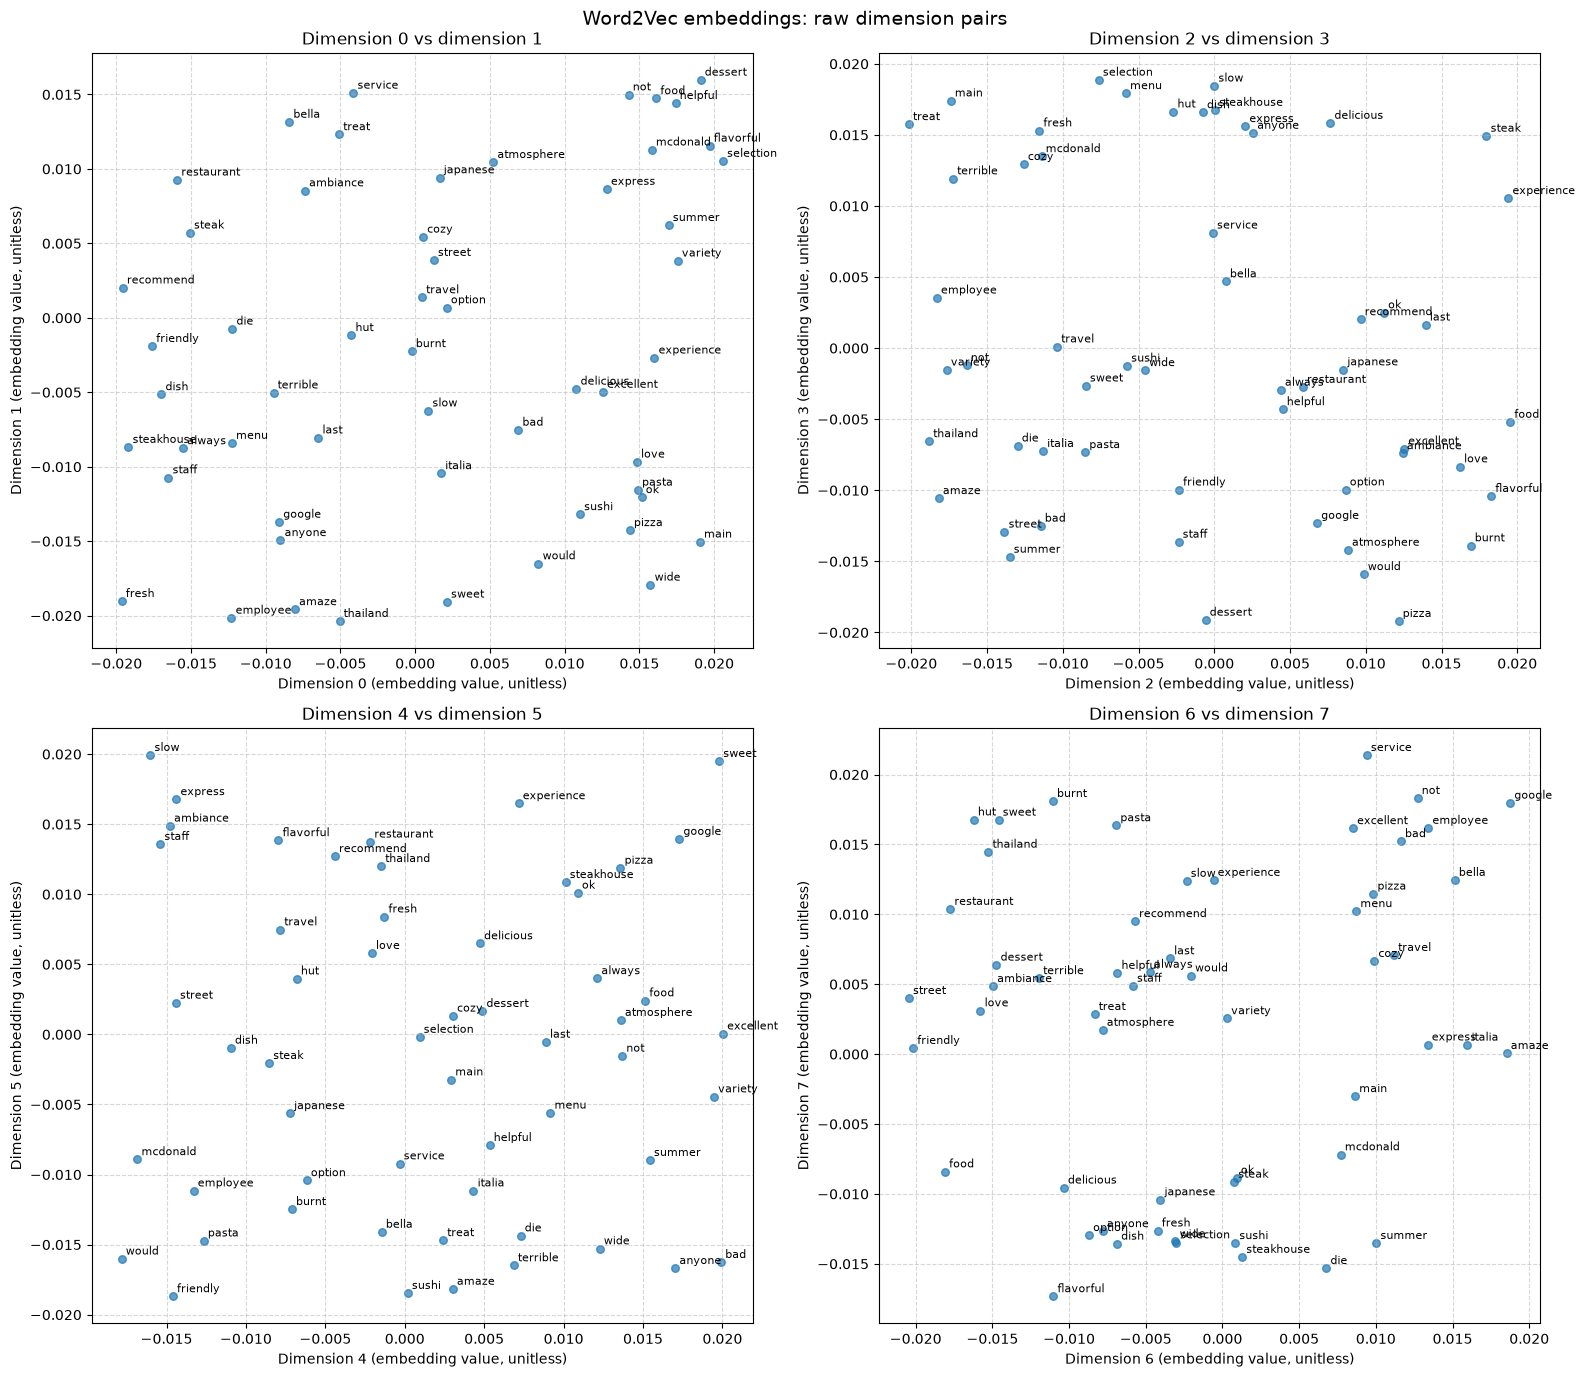

     pizza: [('terrible', 0.31), ('friendly', 0.3), ('express', 0.25), ('love', 0.24)]
   service: [('terrible', 0.32), ('steakhouse', 0.3), ('hut', 0.25), ('variety', 0.23)]
restaurant: [('staff', 0.37), ('google', 0.27), ('steakhouse', 0.26), ('pasta', 0.26)]


In [10]:
import matplotlib.pyplot as plt
import numpy as np


def plot_word_embeddings(model, words=None, dim_pairs=((0, 1), (2, 3), (4, 5), (6, 7))):
    """Scatter-plot pairs of embedding dimensions in a grid, labelling every point."""
    words = words or list(model.wv.index_to_key)
    vectors = np.array([model.wv[word] for word in words])

    n_cols = 2
    n_rows = int(np.ceil(len(dim_pairs) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 7 * n_rows))

    for ax, (x_dim, y_dim) in zip(axes.flat, dim_pairs):
        ax.scatter(vectors[:, x_dim], vectors[:, y_dim], s=30, alpha=0.7)
        for word, x, y in zip(words, vectors[:, x_dim], vectors[:, y_dim]):
            ax.annotate(
                word, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=8
            )
        ax.set_title(f"Dimension {x_dim} vs dimension {y_dim}")
        ax.set_xlabel(f"Dimension {x_dim} (embedding value, unitless)")
        ax.set_ylabel(f"Dimension {y_dim} (embedding value, unitless)")
        ax.grid(True, linestyle="--", alpha=0.5)

    fig.suptitle("Word2Vec embeddings: raw dimension pairs", fontsize=14)
    plt.tight_layout()
    plt.show()


plot_word_embeddings(w2v_model)

# Numbers to back up what the plot shows: the nearest neighbours of a few words
for word in ["pizza", "service", "restaurant"]:
    neighbours = [(w, round(s, 2)) for w, s in w2v_model.wv.most_similar(word, topn=4)]
    print(f"{word:>10}: {neighbours}")


### Analysis · are related words close to each other?

**No.** In every pair of dimensions the 55 words are spread out with no visible groups: food words (`pizza`, `sushi`, `pasta`, `steak`, `dessert`) are not near each other, and positive words (`delicious`, `excellent`, `fresh`) are not separated from negative ones (`terrible`, `bad`, `slow`). The nearest-neighbour check agrees: `pizza`'s closest words are `terrible`, `friendly`, `express`, `love`, and their similarities are only around 0.3.

**Possible reasons**
1. **Far too little data.** Word2Vec learns a word's meaning from the words around it ("you shall know a word by the company it keeps"). We have 10 short reviews, and most words appear exactly once, so each word has one context. A real model sees each word in thousands of sentences.
2. **Related words never share contexts here.** Each review is about a different restaurant, so `pizza` and `pasta` never appear near the same words, and the model has no evidence that they are similar.
3. **The vectors barely trained.** All values are around ±0.02, close to their random initialisation, so the distances between words are mostly noise. A different `seed` would give a completely different picture.
4. **We are looking at 2 of 50 dimensions.** Each panel shows a different arbitrary slice and a different arrangement. PCA (below) summarises all 50 dimensions at once.
5. **Preprocessing removed context.** Dropping stopwords shortens every sentence further, and lemmatization merged unrelated words (the restaurant *Loving* → `love`).

### 2.4 Go further
- Experiment with different preprocessing (e.g., bigrams, stemming vs lemmatization).
- Tune Word2Vec hyperparameters and compare the plots.
- Try dimensionality reduction (PCA/t-SNE) for richer visualizations.

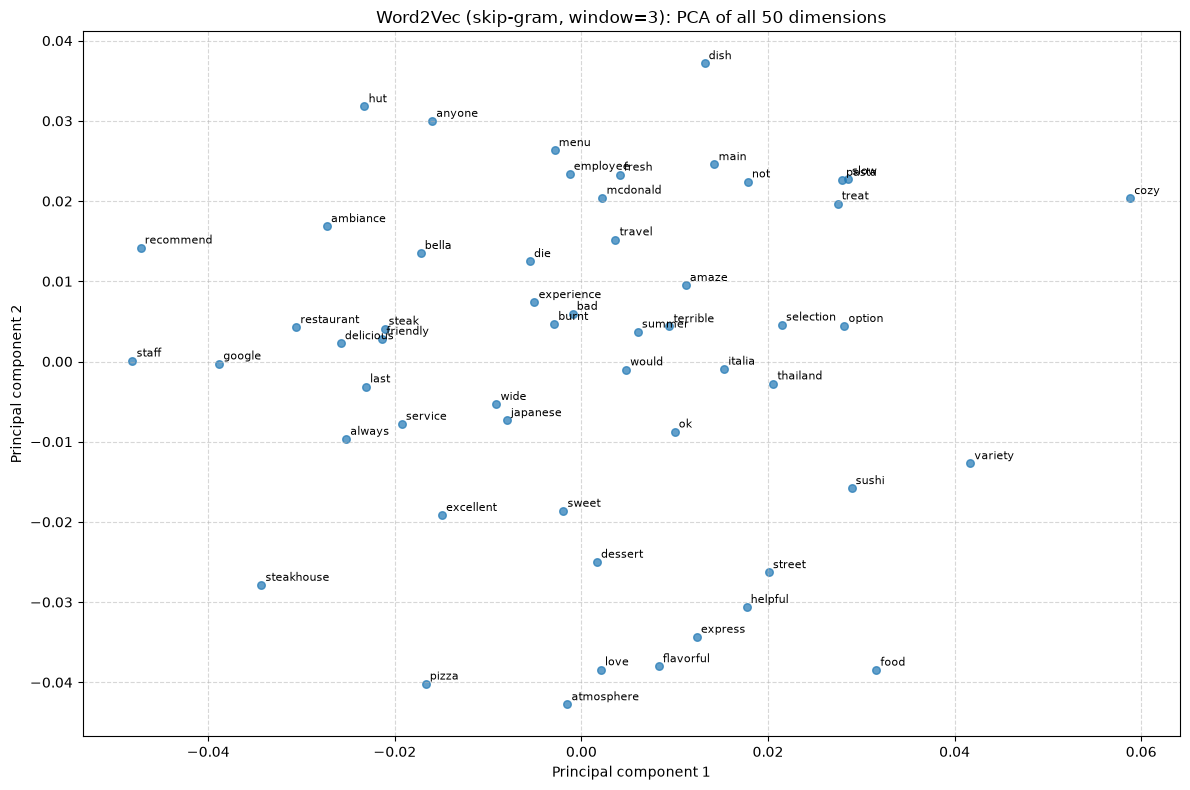

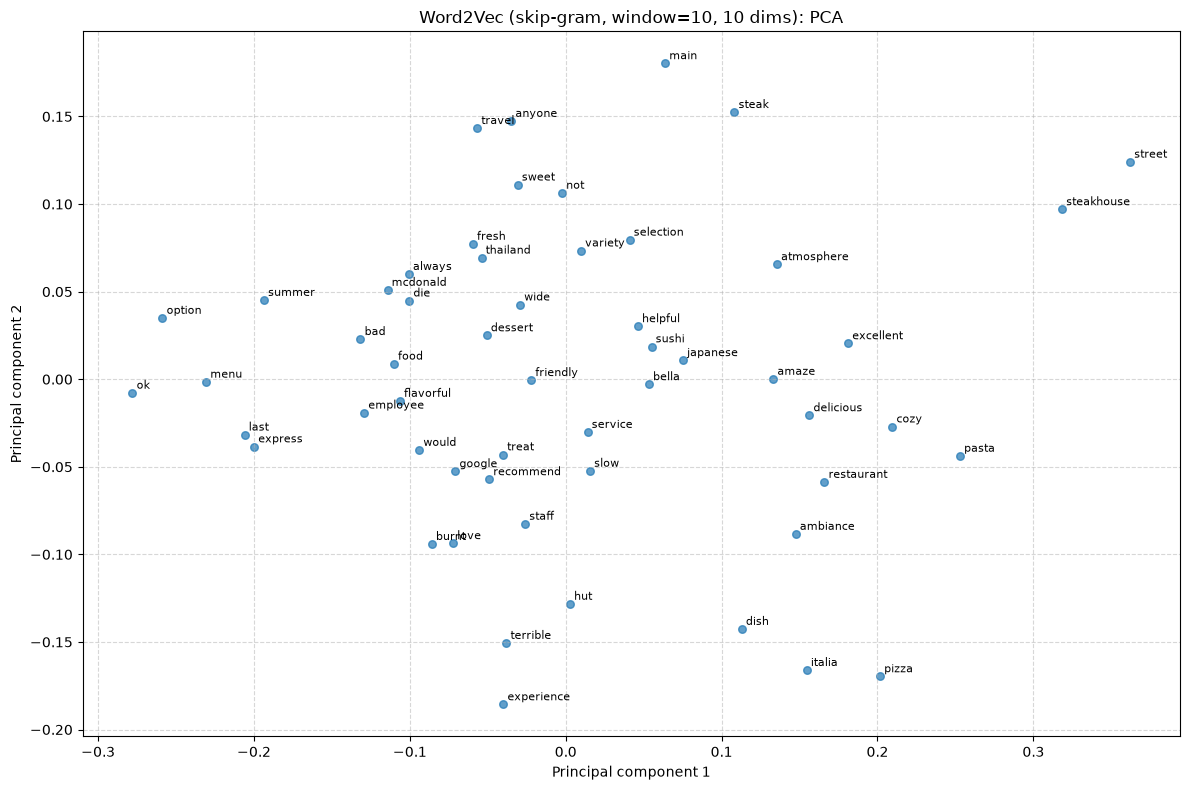

     pizza | base: ['terrible', 'friendly', 'express', 'love'] | tuned: ['italia', 'delicious', 'pasta', 'bella']
   service | base: ['terrible', 'steakhouse', 'hut', 'variety'] | tuned: ['restaurant', 'pasta', 'pizza', 'recommend']
restaurant | base: ['staff', 'google', 'steakhouse', 'pasta'] | tuned: ['pasta', 'excellent', 'service', 'italia']


In [11]:
from sklearn.decomposition import PCA


def plot_pca(model, title):
    """Project all 50 dimensions down to the 2 directions with the most variance."""
    words = list(model.wv.index_to_key)
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
        model.wv[words]
    )
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(coords[:, 0], coords[:, 1], s=30, alpha=0.7)
    for word, (x, y) in zip(words, coords):
        ax.annotate(word, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# PCA uses all 50 dimensions instead of an arbitrary pair, so it is a fairer picture.
plot_pca(w2v_model, "Word2Vec (skip-gram, window=3): PCA of all 50 dimensions")

# Tuned variant: the whole review as context (window=10) and smaller vectors,
# since a 55-word vocabulary cannot support 50 meaningful dimensions.
w2v_tuned = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=10,
    window=10,
    min_count=1,
    sg=1,
    epochs=300,
    seed=RANDOM_STATE,
    workers=1,
)
plot_pca(w2v_tuned, "Word2Vec (skip-gram, window=10, 10 dims): PCA")

for word in ["pizza", "service", "restaurant"]:
    base = [w for w, _ in w2v_model.wv.most_similar(word, topn=4)]
    tuned = [w for w, _ in w2v_tuned.wv.most_similar(word, topn=4)]
    print(f"{word:>10} | base: {base} | tuned: {tuned}")


**What the experiments show**
- The PCA plot uses all 50 dimensions, but the conclusion is the same: no meaningful clusters.
- The tuned model (`window=10`, so the whole review counts as context, and 10 dimensions) returns neighbours that *look* more food-related, e.g. `pizza` → `italia`, `delicious`, `pasta`. Treat this with caution: `pizza` and `pasta` never appear in the same review, so this is not real evidence of similarity. Changing the seed would reshuffle these neighbours.
- No parameter setting can fix the core problem, which is too little text. The real fix is to train on a much larger corpus, or to use **pre-trained** embeddings (Word2Vec / GloVe trained on billions of words, or a sentence-transformer model). That is the next lesson.

## Summary / Findings
- **Preprocessing** (lowercase → tokenize → keep alphabetic tokens → drop stopwords except negations → POS-aware lemmatization) produced clean token lists. It is a set of trade-offs: it lost restaurant names (*Loving* → `love`), and keeping negations was necessary to preserve the meaning of "would not recommend".
- **NER and POS tagging work on raw text and break on cleaned text.** Cleaning made half the reviews lose their entities, gave two more wrong spans, and turned proper nouns and verbs into common nouns. Keep the raw and cleaned versions side by side, and use each for the right job.
- **Word2Vec** trained without errors (55 words × 50 dimensions), but the embeddings carry no real meaning: related words are not close, nearest neighbours are close to random, and tuning the parameters doesn't change that.
- **Limitation:** with 10 sentences, any conclusion about embedding quality is fragile and seed-dependent. Meaningful word embeddings need a large corpus or a pre-trained model.